***LAB ASSIGNMENT 7***

***Part 2: Multinomial Logistic Regression (16 pts)***

In [68]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")  # This suppresses some of the warning output in the saga solver

col_names = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "type"]
glass = pd.read_csv("../data/glass.csv", header=None, names=col_names)

class_names = {1: "building_float", 2: "building_nonfloat", 3: "vehicle_float",
               5: "containers", 6: "tableware", 7: "headlamps"}

features = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]

X = glass[features]
y = glass["type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)

Question 1: [5 pts] Data exploration and model baselines 

1a) Explore the data and make a table looking at the mean, standard deviation, min and max for each of the features. 

In [69]:
#mean, standard deviation, min, and max
X.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
RI,1.52,0.00,1.51,1.53
Na,13.41,0.82,10.73,17.38
Mg,2.68,1.44,0.00,4.49
Al,1.44,0.50,0.29,3.50
Si,72.65,0.77,69.81,75.41
K,0.50,0.65,0.00,6.21
Ca,8.96,1.42,5.43,16.19
Ba,0.18,0.50,0.00,3.15
Fe,0.06,0.10,0.00,0.51


1b) Make a table showing how many glass fragments of each type are in the training set and in the test set. Which glasses are rare? Which is the most common?

ANSWER:
- The glasses type 6 is the rarest following with Type 5 and Type 3. The glasses most common is Type 2.

In [70]:
#training and test sets
class_counts = pd.DataFrame({
    "Training": y_train.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index()
})

class_counts

,Training,Test
type,,
1,56,14
2,61,15
3,14,3
5,10,3
6,7,2
7,23,6


1c) On the training set, what is the accuracy of a “model” that always predicts the most common class?

ANSWER:
The baseline accuracy is 35.67%, so that means that a model that always predicts the most common glass type like Type 2 would correctly classify 35.67% of the training observations.

In [71]:
baseline_accuracy = y_train.value_counts().max() / len(y_train)

baseline_accuracy

np.float64(0.3567251461988304)

1d) Compute the base-rate log loss on the training set. You will want to predict the training class proportions for every glass type, as we did in class.

In [72]:
#training class proportions for every observation
baseline_probs = np.tile(class_proportions.values, (len(y_train), 1))

baseline_probs

array([[0.32748538, 0.35672515, 0.08187135, 0.05847953, 0.04093567,
        0.13450292],
       [0.32748538, 0.35672515, 0.08187135, 0.05847953, 0.04093567,
        0.13450292],
       [0.32748538, 0.35672515, 0.08187135, 0.05847953, 0.04093567,
        0.13450292],
       ...,
       [0.32748538, 0.35672515, 0.08187135, 0.05847953, 0.04093567,
        0.13450292],
       [0.32748538, 0.35672515, 0.08187135, 0.05847953, 0.04093567,
        0.13450292],
       [0.32748538, 0.35672515, 0.08187135, 0.05847953, 0.04093567,
        0.13450292]], shape=(171, 6))

In [73]:
#baseline log loss
baseline_log_loss = log_loss(y_train, baseline_probs)

baseline_log_loss

1.5048600948064486

1e) In the in-class deck, Classification_and_GLMs, I note on slide 56 that predicting 1/K for every class gives a log loss of ln K. For this particular dataset, that would be ln 6. Why is the base-rate log loss from part (d) lower than ln 6?

ANSWER:
The base-rate log loss from part (d) is lower than ln 6 because the six glass types have different frequencies in the training dataset. Also, the base rate model uses actual proportions of each glass type, rather than assigning every type an equal probability of 1/6.

Question 2: [4 pts] Build an unpenalized model (no regularization

2a) The eight oxide columns are weight percentages. (Oxides are every feature but RI) Add them up across each row and summarize the result. What do you find?

ANSWER:
- The mean average is 99.87%, making it very close to 100%
- The STD is 0.12, meaning that it is small and does not vary as much
- The mins starts at 99 and the max ends at 100, but it goes over the 100%

In [74]:
#adding 8 oxide columns
oxides = ["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]

oxide_sum = X[oxides].sum(axis=1)

oxide_sum.describe()

count    214.000000
mean      99.874299
std        0.122126
min       99.020000
25%       99.810000
50%       99.890000
75%       99.960000
max      100.100000
dtype: float64

2b) Fit a multinomial logistic regression with no penalty, 
LogisticRegression(C=np.inf, max_iter=50000), in a pipeline with 
StandardScaler(). Use cross-validation to report the mean log loss and 
accuracy, then fit the model on the full training set and look at its coefficients. 

In [75]:
#multinomial logistic regression with no penalty
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(C=np.inf, max_iter=50000))
])

model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('logistic', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",inf
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",50000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pu

In [76]:
#cross-validation
scores = cross_validate(
    model, X_train, y_train,
    cv=cv,
    scoring=["neg_log_loss", "accuracy"]
)

#mean log loss and accuracy
print("Mean Log Loss:", -scores["test_neg_log_loss"].mean())
print("Mean Accuracy:", scores["test_accuracy"].mean())


Mean Log Loss: 4.258671958351423
Mean Accuracy: 0.626218487394958


In [77]:
#fitting odel on the full training set
model.fit(X_train, y_train)

#coefficients
coef = pd.DataFrame(
    model.named_steps["logistic"].coef_,
    columns=X_train.columns,
    index=model.named_steps["logistic"].classes_
)

coef

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
1,-21.786386,-40.194251,-13.186104,-21.375215,-29.207647,3.773171,-3.962867,2.159877,19.992148
2,-20.530239,-44.902593,-24.727952,-21.893064,-34.103741,0.152243,-14.342708,-2.307225,20.232451
3,-27.296641,-33.369224,-0.103436,-16.763622,-25.197160,6.770262,12.776351,5.188080,19.616103
5,-20.691584,-39.137286,-19.159703,-12.409819,-25.932232,2.812062,-3.822877,1.229648,19.720719
6,42.167766,71.993359,18.254537,39.187603,43.846743,-61.010842,-11.104676,-43.149546,-58.811512
7,48.137084,85.609995,38.922658,33.254118,70.594037,47.503104,20.456777,36.879166,-20.749909


2c) Compute the VIF for each of the nine predictors (as we did in Lab 3). What does this tell us about the coefficients we calculated in Part b, above? Relate your answer to what you found in Part a.

ANSWER:
In part a, we found that the eight oxide percentages add up to approximately 100%, which why the predictors are strongly related. The VIF results show that most predictors have high multicollinearity. This suggests that the coefficients from part b may be unstable and limited. 

In [78]:
#VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif = pd.DataFrame()
vif["Feature"] = X_train.columns
vif["VIF"] = [variance_inflation_factor(X_train.values, i)
              for i in range(X_train.shape[1])]

vif

,Feature,VIF
0,RI,959227.669248
1,Na,18485.920988
2,Mg,1045.242514
3,Al,221.248069
4,Si,483071.693788
5,K,61.247128
6,Ca,10741.985713
7,Ba,38.409246
8,Fe,1.756521


2d) Compare this model’s CV log loss with the base-rate log loss from Q1d. How can 
a model with over 60% accuracy have a worse log loss than a model that uses no 
predictors at all?

ANSWER:
The logistic regression model has over 60% accuracy, but its log loss is higher than the base-rate model. This is because log loss considers how confident the predictions is, when accuracy only measures how often the model predicts the correct type. So when the model makes incorrect predictions with high confidence, it will receive a larger penalty, leading to a higher log loss.

QUESTIOM 3: 5 pts] Build a regularized multinomial logistic regression model.

3a) Plot the mean CV log loss against C for each penalty type, with the base-rate log 
loss as a reference line. Which penalty and C give the lowest CV log loss? Which 
model does the one-standard-error rule select, and how many of its 54 coefficients 
are nonzero? 

In [79]:
#cross-validation
def cv_scores(model):
    res = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=["neg_log_loss"]
    )
    return {
        "log loss (mean)": -res["test_neg_log_loss"].mean(),
        "log loss (sd)": res["test_neg_log_loss"].std()
    }

In [80]:
def make_model(C, l1_ratio):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            C=C,
            l1_ratio=l1_ratio,
            solver="saga",
            max_iter=50000
        ))
    ])

In [81]:
C_values = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]

l1_ratios = {
    "lasso": 1,
    "enet 0.75": 0.75,
    "enet 0.5": 0.5,
    "enet 0.25": 0.25,
    "ridge": 0
}

In [82]:
all_results = pd.DataFrame([
    {"model": name, "C": C, **cv_scores(make_model(C, r))}
    for name, r in l1_ratios.items()
    for C in C_values
])

all_results.round(4)

,model,C,log loss (mean),log loss (sd)
0,lasso,0.01,1.5732,0.0188
1,lasso,0.03,1.5065,0.0209
2,lasso,0.10,1.2993,0.1338
3,lasso,0.30,1.1278,0.2016
4,lasso,1.00,1.1941,0.4244
5,lasso,3.00,1.5078,0.8285
6,lasso,10.00,1.9928,1.3275
7,lasso,30.00,2.2769,1.5558
8,lasso,100.00,2.3839,1.6040
9,lasso,300.00,2.4152,1.6063


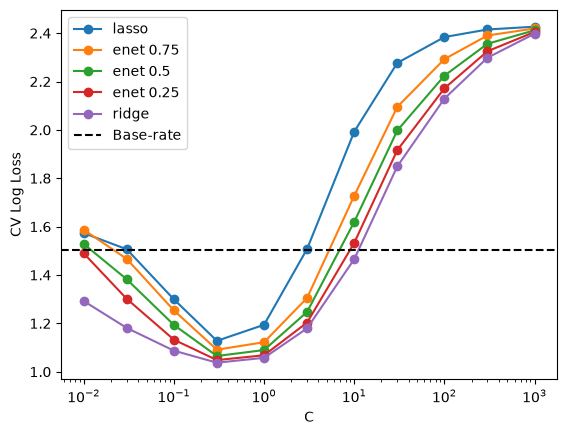

In [83]:
for name in l1_ratios:
    subset = all_results[all_results["model"] == name]
    plt.plot(subset["C"], subset["log loss (mean)"], marker="o", label=name)

plt.axhline(baseline_log_loss, color="black", linestyle="--", label="Base-rate")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("CV Log Loss")
plt.legend()
plt.show()

3b) Plot the mean CV accuracy of each model against C for each penalty type. (This 
is the same plot as in part a, just using accuracy instead of log loss.) Which C has 
the highest accuracy? Compare with the log loss and accuracy of the model in part 
a.

ANSWER: 
Elastic Net with C = 3 has the highest accuracy of 62.66%, while Ridge with C = 0.3 has the lowest log loss of 1.0734. This shows that the model with the highest accuracy does not mean the lowest log loss.

In [84]:
def cv_accuracy(model):
    res = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=["accuracy"]
    )
    return res["test_accuracy"].mean()

In [85]:
accuracy_results = pd.DataFrame([
    {"model": name, "C": C, "accuracy": cv_accuracy(make_model(C, r))}
    for name, r in l1_ratios.items()
    for C in C_values
])

accuracy_results.round(4)

,model,C,accuracy
0,lasso,0.01,0.3452
1,lasso,0.03,0.3511
2,lasso,0.10,0.5383
3,lasso,0.30,0.5913
4,lasso,1.00,0.5973
5,lasso,3.00,0.6150
6,lasso,10.00,0.6091
7,lasso,30.00,0.6091
8,lasso,100.00,0.6205
9,lasso,300.00,0.6205


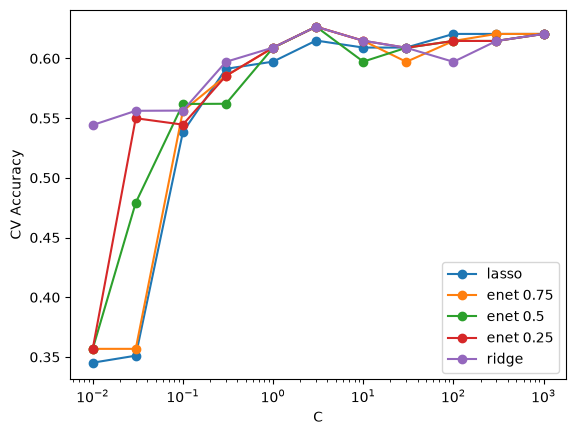

In [86]:
for name in l1_ratios:
    subset = accuracy_results[accuracy_results["model"] == name]
    plt.plot(subset["C"], subset["accuracy"], marker="o", label=name)

plt.xscale("log")
plt.xlabel("C")
plt.ylabel("CV Accuracy")
plt.legend()
plt.show()

In [87]:
best_accuracy = accuracy_results.loc[accuracy_results["accuracy"].idxmax()]
best_accuracy

model       enet 0.75
C                 3.0
accuracy     0.626555
Name: 16, dtype: object

3c) For large values of C (C ≥ 10), every log loss curve sits above the base-rate line. 
Explain why, including what large C means and your answers in Q2. Why is 
accuracy higher than the baseline for large C, but log loss gets worse? 

ANSWER: When accuracy remains higher than the baseline, log loss becomes worse because the model receives a larger penalty when it makes incorrect predictions with high confidence. So when C increases, regularization becomes weaker because the model to makes too confident predictions. 

3d) Fit the selected model from part a on the full training set and make a heatmap of 
its coefficients. Which features have a nonzero coefficient for only one class? 

ANSWER: 
- Fe (Iron) and Ba (Barium) has a nonzero coefficient only for one class


In [88]:
cutoff = best["log loss (mean)"] + best["log loss (sd)"] / np.sqrt(5)

candidates = all_results[all_results["log loss (mean)"] <= cutoff].copy()
candidates["l1_ratio"] = candidates["model"].map(l1_ratios)

candidates

,model,C,log loss (mean),log loss (sd),l1_ratio
14,enet 0.75,0.3,1.091159,0.171118,0.75
25,enet 0.5,0.3,1.065032,0.161790,0.50
26,enet 0.5,1.0,1.089719,0.268786,0.50
36,enet 0.25,0.3,1.048171,0.160989,0.25
37,enet 0.25,1.0,1.068091,0.246942,0.25
46,ridge,0.1,1.087136,0.111340,0.00
47,ridge,0.3,1.037359,0.156085,0.00
48,ridge,1.0,1.057554,0.246615,0.00


In [89]:
candidates["nonzero coefs (of 54)"] = [
    int((make_model(C, r).fit(X_train, y_train).named_steps["model"].coef_ != 0).sum())
    for C, r in zip(candidates["C"], candidates["l1_ratio"])
]

simplest = candidates.sort_values(["nonzero coefs (of 54)", "C"]).iloc[0]

simplest

model                    enet 0.75
C                              0.3
log loss (mean)           1.091159
log loss (sd)             0.171118
l1_ratio                      0.75
nonzero coefs (of 54)           27
Name: 14, dtype: object

In [90]:
C_best = simplest["C"]
l1_best = simplest["l1_ratio"]

model_best = make_model(C_best, l1_best)
model_best.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](6,)","[1,2,3,5,6,7]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['RI','Na','Mg',...,'Ca','Ba','Fe']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


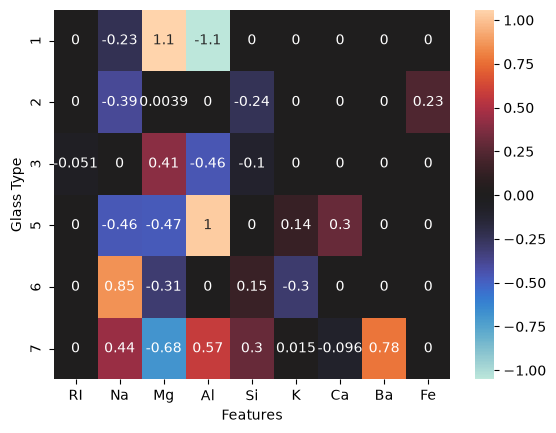

In [91]:
coef = pd.DataFrame(
    model_best.named_steps["model"].coef_,
    columns=X_train.columns,
    index=model_best.named_steps["model"].classes_
)

sns.heatmap(coef, annot=True, center=0)
plt.xlabel("Features")
plt.ylabel("Glass Type")
plt.show()

3e) By what factor does a one standard deviation increase in Ba multiply the odds of 
headlamps vs. building_float? Repeat for Mg, comparing building_float 
vs. headlamps.

In [92]:
np.exp(coef.loc[7, "Ba"] - coef.loc[1, "Ba"])

np.float64(2.1743560124658483)

In [93]:
np.exp(coef.loc[7, "Mg"] - coef.loc[1, "Mg"])

np.float64(0.17504234051877135)

Question 4: [2 pts] Where does the model make mistakes?

4a) Which classes does the model almost never predict correctly? 

ANSWER: 
Glass types 3, 5, and 6 are the classes the model almost never predicts correctly.

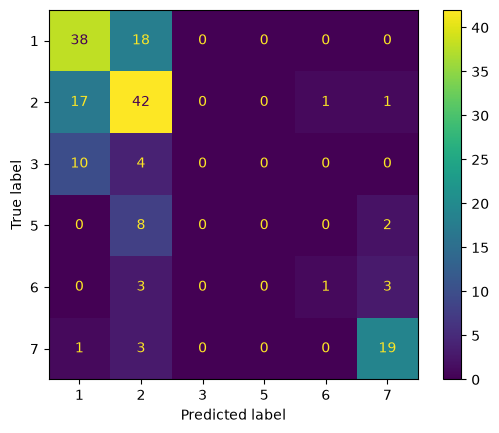

In [94]:
y_pred = cross_val_predict(model_best, X_train, y_train, cv=cv)

ConfusionMatrixDisplay.from_predictions(
    y_train, y_pred
)
plt.show()


4b) Most vehicle_float fragments are predicted as which class? Using the class 
descriptions on the UCI dataset page, why might these two classes be hard to tell 
apart?

ANSWER:
- Most vehicle_float fragments are predicted as building_float
- The two classes may be difficult to distinguish because they have similar manufacturing processes which could result in similar chemical compositions.

***AI usage for part 2:***
I used GenAI to help explain concepts, such as log loss, VIF, multicollinearity, cross validation, and logistic regression, by suggesting beginner-friendly way to approach the problem. I did not rely on the generated answers without checking them with my class notebook examples and I tested the code in Jupyter Notebook.

***Part 3: KNN + Model Comparisons (15 pts)***

Question 1: 4 pts] Choosing k and the distance metric. 

1a) Which (k, p) gives the lowest CV log loss?

ANSWER: 
- (1,1) gives the lowest CV log loss (10.32)

In [95]:
def make_knn(k, p):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k, p=p))
    ])

In [96]:
k_values = list(range(1, 32, 2))

knn_results = pd.DataFrame([
    {
        "k": k,
        "distance": name,
        **cv_scores(make_knn(k, p)),
        "accuracy": cv_accuracy(make_knn(k, p))
    }
    for name, p in {"Manhattan": 1, "Euclidean": 2}.items()
    for k in k_values
])

knn_results.round(3)

,k,distance,log loss (mean),log loss (sd),accuracy
0,1,Manhattan,10.328,1.940,0.713
1,3,Manhattan,4.120,1.073,0.708
2,5,Manhattan,2.815,1.484,0.678
3,7,Manhattan,1.842,1.179,0.661
4,9,Manhattan,1.493,0.727,0.696
5,11,Manhattan,1.530,0.722,0.696
6,13,Manhattan,1.552,0.726,0.708
7,15,Manhattan,1.397,0.474,0.690
8,17,Manhattan,1.437,0.468,0.696
9,19,Manhattan,1.468,0.477,0.661


In [97]:
best_knn = knn_results.loc[
    knn_results["log loss (mean)"].idxmin()
]

best_knn

k                         15
distance           Manhattan
log loss (mean)      1.39673
log loss (sd)       0.474352
accuracy            0.690084
Name: 7, dtype: object

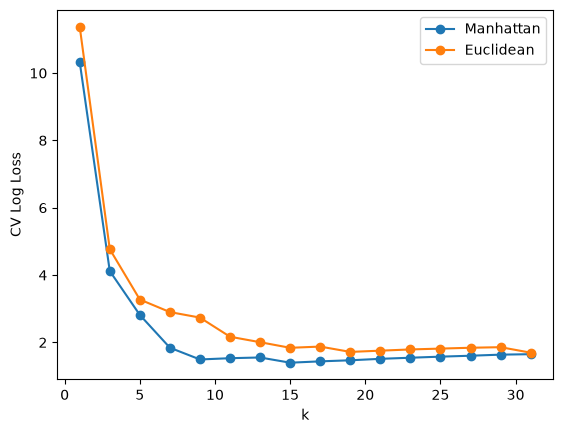

In [98]:
#plot
for name in ["Manhattan", "Euclidean"]:
    subset = knn_results[knn_results["distance"] == name]
    plt.plot(subset["k"], subset["log loss (mean)"],
             marker="o", label=name)

plt.xlabel("k")
plt.ylabel("CV Log Loss")
plt.legend()
plt.show()

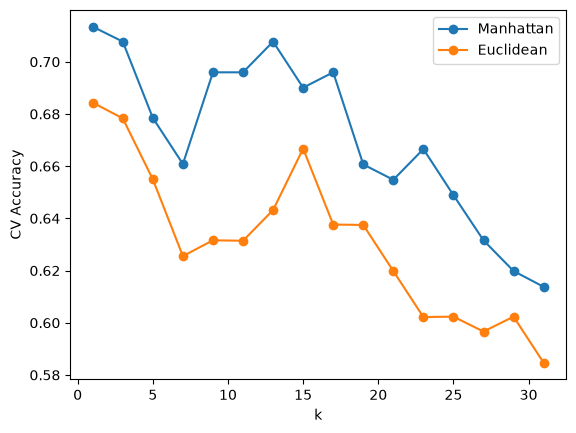

In [99]:
#plot
for name in ["Manhattan", "Euclidean"]:
    subset = knn_results[knn_results["distance"] == name]
    plt.plot(subset["k"], subset["accuracy"],
             marker="o", label=name)

plt.xlabel("k")
plt.ylabel("CV Accuracy")
plt.legend()
plt.show()

1b) If you had chosen k by accuracy instead, which (k, p) would you have picked? 
Explain why that k has one of the best accuracies but by far the worst log loss, 
and why it would be a poor choice.

ANSWER:
If I chose k based on accuracy, I would select k = 1 and p = 1 (Manhattan distance), which has an accuracy of 71.3%. This is the highest accuracy, but it does have a poor log loss. So, even though accuracy is high and log loss is low that means a large penality occurs when the prediction is highly incorrect.

Question 2: 2 pts] Where does KNN’s log loss come from?

2a) How many fragments get a probability of exactly 0 for their true class? Which 
classes are they from? 

ANSWER: 
A total of 3 glass fragments receives a predicted probability of exactly 0 for their true class such as Class 5 and Class 7.

In [100]:
knn_best = make_knn(15, 1)

probs = cross_val_predict(
    knn_best, X_train, y_train,
    cv=cv, method="predict_proba"
)

probs

array([[0.        , 0.        , 0.        , 0.        , 0.13333333,
        0.86666667],
       [0.33333333, 0.2       , 0.        , 0.13333333, 0.26666667,
        0.06666667],
       [0.2       , 0.06666667, 0.2       , 0.2       , 0.33333333,
        0.        ],
       ...,
       [0.13333333, 0.73333333, 0.13333333, 0.        , 0.        ,
        0.        ],
       [0.66666667, 0.2       , 0.13333333, 0.        , 0.        ,
        0.        ],
       [0.33333333, 0.53333333, 0.13333333, 0.        , 0.        ,
        0.        ]], shape=(171, 6))

In [101]:
classes = np.array([1, 2, 3, 5, 6, 7])

true_probs = probs[
    np.arange(len(y_train)),
    np.searchsorted(classes, y_train)
]

true_probs

array([0.86666667, 0.2       , 0.06666667, 0.66666667, 0.53333333,
       0.46666667, 0.66666667, 0.73333333, 0.13333333, 0.86666667,
       0.4       , 0.46666667, 0.        , 0.66666667, 0.53333333,
       0.53333333, 0.6       , 0.13333333, 0.86666667, 0.13333333,
       0.73333333, 0.6       , 0.26666667, 0.53333333, 0.6       ,
       0.93333333, 0.93333333, 0.6       , 0.13333333, 0.53333333,
       0.66666667, 0.6       , 0.33333333, 0.93333333, 0.4       ,
       1.        , 0.26666667, 0.93333333, 0.86666667, 0.73333333,
       0.86666667, 0.46666667, 0.53333333, 0.46666667, 0.53333333,
       0.66666667, 0.26666667, 0.4       , 0.8       , 0.33333333,
       0.33333333, 0.        , 0.73333333, 0.2       , 0.73333333,
       0.2       , 0.4       , 0.46666667, 0.53333333, 0.13333333,
       0.53333333, 0.33333333, 0.06666667, 0.2       , 0.6       ,
       0.4       , 0.06666667, 0.4       , 0.8       , 0.26666667,
       0.33333333, 0.8       , 0.8       , 0.86666667, 0.53333

In [102]:
zero_probs = true_probs == 0

print("Number of fragments:", zero_probs.sum())
print("Glass classes:")
print(y_train[zero_probs].value_counts().sort_index())

Number of fragments: 3
Glass classes:
type
5    1
7    2
Name: count, dtype: int64


2b) Before taking the log, sklearn replaces a probability of 0 with a tiny number, 
np.finfo(float).eps (about 2.2 × 10⁻¹⁶). For the fragments identified above in 
Part a, how much does each one add to the log loss? What percentage of the total 
KNN log loss comes from these fragments? What is the mean log loss of the 
remaining fragments? 

ANSWER:
- For each of the fragments it adds about 36.04 to the log-loss
- The three fragments account for about 45.20 of the total log loss
- The remaining 168 fragments have a mean log loss of about 0.7804

In [103]:
penalty = -np.log(np.finfo(float).eps)
penalty

np.float64(36.04365338911715)

In [104]:
total_loss = -np.log(np.clip(true_probs, np.finfo(float).eps, 1))

percentage = total_loss[zero_probs].sum() / total_loss.sum() * 100

percentage

np.float64(45.196678974324314)

In [105]:
remaining_loss = total_loss[~zero_probs].mean()
remaining_loss

np.float64(0.7804428936440069)

Question 3: 6 pts] Comparing the two models

3a) Compare the CV log loss and CV accuracy of your selected logistic model and 
your selected KNN. Make a second table that shows recall for each class 
(recall_score(..., average=None)) for both models. Which model has the 
lower CV log loss?

ANSWER:
Elastic Net logistic regression has the lower CV log loss

In [106]:
accuracy_results[
    (accuracy_results["model"] == "enet 0.75") &
    (accuracy_results["C"] == 0.3)
]

,model,C,accuracy
14,enet 0.75,0.3,0.585378


In [107]:
y_pred_knn = cross_val_predict(knn_best, X_train, y_train, cv=cv)

recall_knn = recall_score(y_train, y_pred_knn, average=None)

recall_knn

array([0.96428571, 0.72131148, 0.        , 0.2       , 0.        ,
       0.7826087 ])

In [108]:
y_pred_logistic = cross_val_predict(model_best, X_train, y_train, cv=cv)

recall_logistic = recall_score(y_train, y_pred_logistic, average=None)

recall_logistic

array([0.67857143, 0.68852459, 0.        , 0.        , 0.14285714,
       0.82608696])

In [109]:
recall_table = pd.DataFrame({
    "Glass Class": [1, 2, 3, 5, 6, 7],
    "Logistic Regression": recall_logistic,
    "KNN": recall_knn
})

recall_table.round(3)

,Glass Class,Logistic Regression,KNN
0,1,0.679,0.964
1,2,0.689,0.721
2,3,0.000,0.000
3,5,0.000,0.200
4,6,0.143,0.000
5,7,0.826,0.783


3b) Compare the confusion matrices for each model. Using the confusion matrices for 
each model, explain where KNN’s extra accuracy comes from and why it isn’t a 
good reason to prefer KNN. 

ANSWER:
- KNN has higher accuracy because it correctly predicts more glass fragments when it came to class 1.  
- KNN also has a higher CV log loss (1.3967) compared to logistic regression (1.0912). So, predicted probabilities are not as reliable leading to not just depending on high accuracy to make it a better model for KNN.

In [110]:
cm_knn = confusion_matrix(y_train, y_pred_knn)

pd.DataFrame(
    cm_knn,
    index=[1, 2, 3, 5, 6, 7],
    columns=[1, 2, 3, 5, 6, 7]
)

,1,2,3,5,6,7
1,54,2,0,0,0,0
2,16,44,0,0,1,0
3,12,2,0,0,0,0
5,3,4,0,2,0,1
6,2,1,0,1,0,3
7,4,1,0,0,0,18


3c) Using the recall table, which glass classes does KNN handle better, and which 
does it not help? What does this suggest about the shape of the boundaries 
between some of the glass classes? 

ANSWER:
KNN has the ability to capture more flexible boundaries, allowing it to correctly classify more class 1 fragments than logistic regression. In addition, the decision boundaries may be irregular because KNN’s recall for class 1 is higher.

Question 4: [3 pts] Evaluate on the test set.

4a) [1 pt] Do the test results rank the two models the same way cross-validation did? 

ANSWER:
No the test do not rank the models the same way as cross-validation

In [111]:
model_best.fit(X_train, y_train)

knn_best.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](6,)","[1,2,3,5,6,7]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['RI','Na','Mg',...,'Ca','Ba','Fe']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [112]:
logistic_probs = model_best.predict_proba(X_test)
logistic_preds = model_best.predict(X_test)

print("Logistic Test Log Loss:", log_loss(y_test, logistic_probs))
print("Logistic Test Accuracy:", accuracy_score(y_test, logistic_preds))

Logistic Test Log Loss: 0.8864458663606902
Logistic Test Accuracy: 0.6511627906976745


In [113]:
knn_probs = knn_best.predict_proba(X_test)
knn_preds = knn_best.predict(X_test)

print("KNN Test Log Loss:", log_loss(y_test, knn_probs))
print("KNN Test Accuracy:", accuracy_score(y_test, knn_preds))

KNN Test Log Loss: 0.7537933937213117
KNN Test Accuracy: 0.627906976744186


In [114]:
cm_logistic_test = confusion_matrix(y_test, logistic_preds)

pd.DataFrame(
    cm_logistic_test,
    index=[1, 2, 3, 5, 6, 7],
    columns=[1, 2, 3, 5, 6, 7]
)

,1,2,3,5,6,7
1,10,4,0,0,0,0
2,5,10,0,0,0,0
3,2,1,0,0,0,0
5,0,1,0,2,0,0
6,0,2,0,0,0,0
7,0,0,0,0,0,6


In [115]:
cm_knn_test = confusion_matrix(y_test, knn_preds)

pd.DataFrame(
    cm_knn_test,
    index=[1, 2, 3, 5, 6, 7],
    columns=[1, 2, 3, 5, 6, 7]
)

,1,2,3,5,6,7
1,13,1,0,0,0,0
2,7,8,0,0,0,0
3,3,0,0,0,0,0
5,0,3,0,0,0,0
6,2,0,0,0,0,0
7,0,0,0,0,0,6


4b) [2 pts] The test set has only 43 fragments, with 2 tableware fragments and 3 each 
of vehicle_float and containers. What can and can’t you conclude about per-class 
performance from these results? How much would a single fragment with a 
predicted probability of 0 for its true class add to KNN’s test log loss?

ANSWER:
- Tableware has only 2 fragments, while vehicle_float and containers have 3 each. So, a single fragment with a predicted probability of 0 would add approximately 0.83 to KNN's mean test log loss.
- You can conclude that matrices show how well each model classified the glass fragments in test set, but you cannot conclude how reliable the models perform on each glass class.

***AI usage for part 3:***
I used GenAI to help explain concepts, such as log loss, KNN, cross validation, and matrices by suggesting beginner-friendly way to approach the problem. I did not rely on the generated answers without checking them with my class notebook examples and I tested the code in Jupyter Notebook.